# Modelo de predicción de no afiliación a salud

En este notebook entrenamos un modelo supervisado que predice si una persona de la encuesta ASP 2022 **no tiene afiliación al sistema de salud**, a partir de sus características sociodemográficas y de la localidad donde vive. Los pasos son:

- Preparar la variable objetivo y las variables de entrada
- Entrenar una regresión logística como línea base
- Entrenar modelos de ensamble (Random Forest y Gradient Boosting)
- Optimizar hiperparámetros con validación cruzada
- Evaluar el mejor modelo con datos que no vio
- Interpretar el modelo con SHAP
- Guardar el modelo para el endpoint de AWS

In [9]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

In [10]:
#cargamos el dataset limpio (el mismo que usamos para el clustering)
df = pd.read_csv("../data/processed/asp_2022_variables_limpio.csv")
print("Filas y columnas:", df.shape)

df["afiliado_seg_social_salud"].value_counts()

Filas y columnas: (3003, 50)


afiliado_seg_social_salud
Sí                     1499
No                     1492
No sabe/No responde      12
Name: count, dtype: int64

# Variable objetivo

La propuesta planteaba tres clases (afiliado / no afiliado / desconocido), pero "No sabe/No responde" son solo 12 personas (0,4 %): no alcanza para que un modelo aprenda esa clase. Por eso la dejamos **binaria**:

- **1 = NO afiliada** (es lo que queremos detectar)
- **0 = afiliada**

y quitamos las 12 personas sin respuesta. Las clases quedan **balanceadas** (casi 50 % y 50 %), así que no hace falta remuestreo.

In [11]:
#quitamos a quienes no saben o no respondieron
df = df[df["afiliado_seg_social_salud"] != "No sabe/No responde"].reset_index(drop=True)

#variable objetivo: 1 = NO afiliada, 0 = afiliada
y = (df["afiliado_seg_social_salud"] == "No").astype(int)

print("Personas:", len(df))
print("Proporción de NO afiliadas: %0.3f" % y.mean())

Personas: 2991
Proporción de NO afiliadas: 0.499


# Variables de entrada

Usamos **las mismas 18 variables del clustering** con la misma transformación, para que el modelo y los perfiles hablen el mismo idioma. Para no copiar los diccionarios a mano, los leemos del archivo `clustering_config.json` que guardamos en el notebook de minería.

Además agregamos **3 indicadores de la localidad** (de SaluData) que pide la propuesta: pobreza monetaria 2021, coeficiente de Gini 2021 y % de afiliados al régimen subsidiado en 2022.

**Variables que NO entran (fuga de información):** `regimen_salud`, las preguntas de barreras en salud, `atencion_medica_ult_anio` y similares. Solo se les preguntaron a quienes están afiliadas o dependen de estar afiliada: si las usamos, el modelo "haría trampa" con información que ya revela la respuesta.

**Tampoco usamos `cluster` como variable:** se calcula con las mismas 18 variables, así que no aporta información nueva.

In [12]:
#diccionarios de recodificación guardados en el notebook de minería
with open("modelos/clustering_config.json", encoding="utf-8") as archivo:
    config = json.load(archivo)

variables = config["variables"]   #las 18 variables, en el mismo orden del clustering
print(variables)

['edad', 'personas_hogar', 'dependientes_economicos', 'autopercepcion_nivel_economico', 'horas_semana_asp', 'edad_inicio_asp', 'tiempo_viviendo_bogota', 'nivel_educativo', 'tipo_vivienda', 'migrante', 'grupo_etnico', 'victima_conflicto_armado', 'ingresos_insuficientes', 'paga_intermediario_tercero', 'discriminacion_general', 'amenazas_recibidas', 'forzada_relaciones_sexuales', 'violencia_fuerza_publica']


In [13]:
#tomamos las columnas originales del CSV
columnas_originales = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
                       "horas_semana_asp", "edad_inicio_asp", "tiempo_viviendo_bogota", "nivel_educativo",
                       "tipo_vivienda", "pais_nacimiento", "autoreconocimiento_etnico", "victima_conflicto_armado",
                       "ingresos_suficientes_gastos", "paga_intermediario_tercero", "discriminacion_general",
                       "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]
X = df[columnas_originales].copy()

#"No sabe/No responde" -> moda (igual que en minería)
for col in X.columns:
    if X[col].dtype != "int64" and X[col].dtype != "float64":
        moda = X[col][X[col] != "No sabe/No responde"].mode()[0]
        X[col] = X[col].replace("No sabe/No responde", moda)

#ordinales con los diccionarios del JSON
for col, diccionario in config["recodificacion"].items():
    X[col] = X[col].map(diccionario)

#binarias a 1 y 0
X["pais_nacimiento"] = (X["pais_nacimiento"] != "Colombia").astype(int)
X["autoreconocimiento_etnico"] = (X["autoreconocimiento_etnico"] != "Ninguno").astype(int)
X["ingresos_suficientes_gastos"] = (X["ingresos_suficientes_gastos"] == "No").astype(int)
for col in ["victima_conflicto_armado", "paga_intermediario_tercero", "discriminacion_general",
            "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]:
    X[col] = (X[col] == "Sí").astype(int)

X = X.rename(columns={"pais_nacimiento": "migrante",
                      "autoreconocimiento_etnico": "grupo_etnico",
                      "ingresos_suficientes_gastos": "ingresos_insuficientes"})

#comprobamos que quedaron igual que en el clustering
print("Mismas variables y orden que el clustering:", list(X.columns) == variables)

Mismas variables y orden que el clustering: True


In [14]:
#indicadores de la localidad (un valor por localidad) desde la base integrada con SaluData
indicadores = pd.read_csv("../data/processed/asp_2022_saludata_integrado.csv")
indicadores = indicadores[["localidad", "pobreza_monetaria_pct_2021", "gini_2021",
                           "subsidiado_pct_propio_2022"]].drop_duplicates()
print("Localidades con indicadores:", len(indicadores))

#pegamos los indicadores a cada persona según su localidad
X["localidad"] = df["localidad"]
X = X.merge(indicadores, on="localidad", how="left").drop(columns="localidad")

print("Valores vacíos:", X.isnull().sum().sum())
print("Filas y columnas de X:", X.shape)
X.head()

Localidades con indicadores: 19
Valores vacíos: 0
Filas y columnas de X: (2991, 21)


,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,horas_semana_asp,edad_inicio_asp,tiempo_viviendo_bogota,nivel_educativo,tipo_vivienda,migrante,...,victima_conflicto_armado,ingresos_insuficientes,paga_intermediario_tercero,discriminacion_general,amenazas_recibidas,forzada_relaciones_sexuales,violencia_fuerza_publica,pobreza_monetaria_pct_2021,gini_2021,subsidiado_pct_propio_2022
0,19,1,0,5,48,18,0,4,0,0,...,0,1,1,0,0,0,0,23.94,0.46,14.39
1,26,1,2,4,48,26,1,5,1,1,...,0,1,1,0,0,0,0,23.94,0.46,14.39
2,21,7,4,5,48,21,1,2,0,1,...,0,1,1,0,1,1,1,23.94,0.46,14.39
3,20,2,0,1,42,16,0,3,2,0,...,0,0,0,0,0,0,0,23.94,0.46,14.39
4,20,1,4,1,56,16,0,2,2,1,...,0,1,0,0,0,0,0,23.94,0.46,14.39


# Separación en entrenamiento y prueba

Separamos el **20 % de las personas como conjunto de prueba** y no lo tocamos hasta el final: es como un examen con preguntas que el modelo nunca vio. Con el 80 % restante entrenamos y comparamos modelos usando validación cruzada.

Usamos `stratify=y` para que ambos conjuntos tengan la misma proporción de personas no afiliadas.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)

print("Entrenamiento:", X_train.shape, " Proporción NO afiliadas: %0.3f" % y_train.mean())
print("Prueba:       ", X_test.shape, " Proporción NO afiliadas: %0.3f" % y_test.mean())

Entrenamiento: (2392, 21)  Proporción NO afiliadas: 0.499
Prueba:        (599, 21)  Proporción NO afiliadas: 0.499


# Línea base: regresión logística

La regresión logística estima la **probabilidad de no estar afiliada** combinando las variables con un peso (coeficiente) cada una. Es simple e interpretable, por eso la usamos como punto de comparación.

**Validación cruzada (5 folds):** dividimos el conjunto de entrenamiento en 5 partes; entrenamos con 4 y evaluamos con la que queda, rotando 5 veces. Así cada resultado se mide con datos que el modelo no vio, y el promedio es más confiable que una sola división.

**Métricas** (para la clase 1 = NO afiliada):

- **AUC**: qué tan bien ordena a las personas de mayor a menor riesgo. 0,5 = al azar, 1 = perfecto. Es la métrica principal.
- **Recall**: de todas las personas que **realmente** no están afiliadas, qué porcentaje detecta el modelo.
- **Precisión**: de las personas que el modelo **marca** como no afiliadas, qué porcentaje realmente lo es.
- **F1**: combina recall y precisión en un solo número.
- **Exactitud (accuracy)**: porcentaje total de aciertos. Como las clases están balanceadas sí es interpretable, pero no es la principal.

In [16]:
#validación cruzada estratificada: 5 partes con la misma proporción de no afiliadas
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#métricas que vamos a calcular en cada parte
metricas = ["roc_auc", "f1", "recall", "precision", "accuracy"]

#pipeline: primero escalar, después la regresión logística
modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("logistica", LogisticRegression(max_iter=1000))
])

In [17]:
#entrenamos y evaluamos 5 veces
resultados_log = cross_validate(modelo_logistico, X_train, y_train,
                                cv=validacion, scoring=metricas)

#tabla con el resultado de cada parte
tabla_log = pd.DataFrame({m: resultados_log["test_" + m] for m in metricas})
tabla_log.index = ["Parte " + str(i + 1) for i in range(5)]

print("Promedio:\n", tabla_log.mean().round(3))
print("\nDesviación estándar:\n", tabla_log.std().round(3))
tabla_log.round(3)

Promedio:
 roc_auc      0.855
f1           0.808
recall       0.757
precision    0.867
accuracy     0.821
dtype: float64

Desviación estándar:
 roc_auc      0.025
f1           0.028
recall       0.034
precision    0.034
accuracy     0.026
dtype: float64


,roc_auc,f1,recall,precision,accuracy
Parte 1,0.864,0.817,0.757,0.887,0.831
Parte 2,0.827,0.772,0.715,0.838,0.789
Parte 3,0.831,0.793,0.765,0.824,0.801
Parte 4,0.885,0.846,0.807,0.889,0.854
Parte 5,0.867,0.812,0.741,0.898,0.828


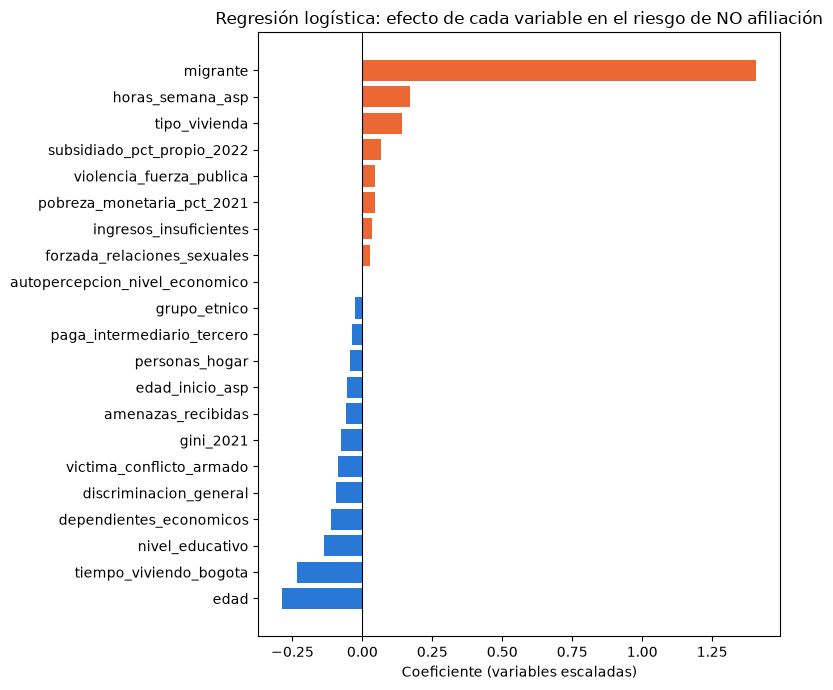

In [18]:
#entrenamos con todo el conjunto de entrenamiento para ver los coeficientes
modelo_logistico.fit(X_train, y_train)

coeficientes = pd.Series(modelo_logistico.named_steps["logistica"].coef_[0],
                         index=X_train.columns).sort_values()

#gráfica: positivo = aumenta el riesgo de NO estar afiliada, negativo = lo disminuye
plt.figure(figsize=(8, 7), dpi=100)
colores_coef = ["#eb6834" if c > 0 else "#2a78d6" for c in coeficientes]
plt.barh(coeficientes.index, coeficientes.values, color=colores_coef)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente (variables escaladas)")
plt.title("Regresión logística: efecto de cada variable en el riesgo de NO afiliación")
plt.tight_layout()
plt.show()

**Resultados de la línea base** (validación cruzada, 5 partes):

- **AUC = 0,855**: el modelo ordena bien a las personas según su riesgo.
- **Precisión = 0,87** y **recall = 0,76**: cuando el modelo marca a alguien como no afiliada casi siempre acierta, pero **deja sin detectar a cerca de 1 de cada 4** personas no afiliadas. Para una herramienta de focalización de política pública, ese recall es lo que más conviene mejorar.

**Coeficientes:** el factor que más pesa, por mucho, es **ser migrante** (coeficiente 1,41, cinco veces más que el siguiente). Le siguen la **edad** y el **tiempo viviendo en Bogotá**: las personas más jóvenes y recién llegadas tienen más riesgo. Los indicadores de localidad tienen coeficientes muy pequeños.

Esto coincide con los perfiles del clustering: el perfil "Migrantes de llegada reciente" es el de menor afiliación.